# Earthquake Ground Motion Directionality: Complete Pipeline

Run this notebook from top to bottom to execute the complete project pipeline. It regenerates the synthetic dataset, selects features, trains and tunes the models, evaluates them, displays and saves the publication figures, runs the demonstration scenarios, and performs an example prediction. The existing PDF deliverable is preserved and is not regenerated.

In [17]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / 'earthquake_directionality_pipeline.ipynb').exists():
    project_root = project_root.parent
if not (project_root / 'earthquake_directionality_pipeline.ipynb').exists():
    raise FileNotFoundError('Open this notebook inside the project directory.')

DATA_DIR = project_root / 'data'
MODELS_DIR = project_root / 'models'
FIGURES_DIR = project_root / 'figures'
DELIVERABLES_DIR = project_root / 'deliverables'
for output_dir in (DATA_DIR, MODELS_DIR, FIGURES_DIR, DELIVERABLES_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / 'nga_west2_paired_sites.csv'
SELECTED_FEATURES_PATH = DATA_DIR / 'selected_features.json'
RANDOM_SEED = 42
RIDGE_ALPHA_DEFAULT = 1.5
NN_ALPHA_DEFAULT = 0.1
np.random.seed(RANDOM_SEED)

# The original project logic is kept here so the notebook is the only code entry point.
def generate_nga_west2_synthetic(target_pairs=5300, seed=RANDOM_SEED):
    rng = np.random.RandomState(seed)
    rows = []
    for eq_id in range(1, 86):
        mw = rng.uniform(5.0, 7.6)
        mechanism = rng.choice(['strike_slip', 'reverse', 'normal'], p=[0.55, 0.30, 0.15])
        if mechanism == 'strike_slip':
            dip, rake = rng.uniform(70, 90), rng.choice([0, 180]) + rng.normal(0, 10)
        elif mechanism == 'reverse':
            dip, rake = rng.uniform(30, 60), rng.uniform(70, 110)
        else:
            dip, rake = rng.uniform(40, 65), rng.uniform(-110, -70)
        strike = rng.uniform(0, 360)
        area = 10 ** (mw - 4.0 + rng.normal(0, 0.15))
        rup_len = np.sqrt(area * rng.uniform(1.5, 3.5))
        rup_width = area / rup_len
        zhyp = rng.uniform(5.0, 22.0)
        ztor = max(0.0, zhyp - rup_width * np.sin(np.radians(dip)) * rng.uniform(0.3, 0.8))
        stations = []
        for _ in range(rng.randint(3, 7)):
            cluster_dist = rng.exponential(22.0) + 5.0
            azimuth = rng.uniform(0, 2 * np.pi)
            cx, cy = cluster_dist * np.cos(azimuth), cluster_dist * np.sin(azimuth)
            for _ in range(rng.randint(6, 16)):
                sx, sy = cx + rng.normal(0, 1.25), cy + rng.normal(0, 1.25)
                repi = np.hypot(sx, sy)
                rhyp = np.sqrt(repi ** 2 + zhyp ** 2)
                rjb = max(0.0, repi - rup_len * 0.3)
                rrup = np.sqrt(rjb ** 2 + ztor ** 2)
                vs30 = np.clip(rng.choice([250, 360, 480, 760], p=[0.25, 0.45, 0.20, 0.10]) + rng.normal(0, 45), 160, 1200)
                nehrp = 'B' if vs30 > 760 else 'C' if vs30 > 360 else 'D' if vs30 > 180 else 'E'
                pga = np.exp(-0.6 + 0.38 * mw - 1.18 * np.log(np.sqrt(rrup ** 2 + 7.5 ** 2)) - 0.22 * np.log(vs30 / 760) + rng.normal(0, 0.30))
                pgv = np.exp(-1.1 + 0.58 * mw - 1.05 * np.log(np.sqrt(rrup ** 2 + 5.0 ** 2)) - 0.32 * np.log(vs30 / 760) + rng.normal(0, 0.35))
                pgd = np.exp(-2.4 + 0.76 * mw - 0.95 * np.log(np.sqrt(rrup ** 2 + 5.0 ** 2)) + rng.normal(0, 0.40))
                stations.append(dict(x=sx, y=sy, repi=repi, rhyp=rhyp, rjb=rjb, rrup=rrup, vs30=vs30, nehrp=nehrp, pga=pga, pgv=pgv, pgd=pgd))
        for i, first in enumerate(stations):
            for second in stations[i + 1:]:
                distance = np.hypot(first['x'] - second['x'], first['y'] - second['y'])
                if distance > 5.0:
                    continue
                avg_pga = (first['pga'] + second['pga']) / 2
                avg_pgv = (first['pgv'] + second['pgv']) / 2
                avg_vs30 = (first['vs30'] + second['vs30']) / 2
                rows.append({
                    'eq_id': eq_id, 'earthquake_magnitude': mw, 'focal_mechanism': mechanism,
                    'strike_angle': strike, 'dip_angle': dip, 'rake_angle': rake,
                    'fault_rupture_length': rup_len, 'fault_rupture_width': rup_width, 'fault_rupture_area': area,
                    'hypocenter_depth': zhyp, 'ztor_depth': ztor, 'distance_between_sites': distance,
                    's1_vs30': first['vs30'], 's1_nehrp': first['nehrp'], 's1_repi': first['repi'], 's1_rhyp': first['rhyp'],
                    's1_rjb': first['rjb'], 's1_rrup': first['rrup'], 's1_pga': first['pga'], 's1_pgv': first['pgv'], 's1_pgd': first['pgd'],
                    's2_vs30': second['vs30'], 's2_nehrp': second['nehrp'], 's2_repi': second['repi'], 's2_rhyp': second['rhyp'],
                    's2_rjb': second['rjb'], 's2_rrup': second['rrup'], 's2_pga': second['pga'], 's2_pgv': second['pgv'], 's2_pgd': second['pgd'],
                    'average_pga': avg_pga, 'average_pgv': avg_pgv, 'average_pgd': (first['pgd'] + second['pgd']) / 2,
                    'average_vs30': avg_vs30, 'average_rrup': (first['rrup'] + second['rrup']) / 2,
                    'average_rhyp': (first['rhyp'] + second['rhyp']) / 2, 'diff_pga': abs(first['pga'] - second['pga']),
                    'diff_pgv': abs(first['pgv'] - second['pgv']), 'diff_vs30': abs(first['vs30'] - second['vs30']),
                    'diff_rrup': abs(first['rrup'] - second['rrup']), 'ratio_pga': first['pga'] / (second['pga'] + 1e-5),
                    'ratio_vs30': first['vs30'] / (second['vs30'] + 1e-5)
                })
        if len(rows) >= target_pairs + 500:
            break
    df = pd.DataFrame(rows).sample(n=target_pairs, random_state=seed).reset_index(drop=True)
    df['log_pga_avg'] = np.log10(df.average_pga + 1e-4)
    df['log_pgv_avg'] = np.log10(df.average_pgv + 1e-4)
    df['log_vs30_avg'] = np.log10(df.average_vs30)
    df['rup_distance_ratio'] = df.s1_rrup / (df.s2_rrup + 1e-3)
    df['hypo_distance_ratio'] = df.s1_rhyp / (df.s2_rhyp + 1e-3)
    df['seismic_moment_proxy'] = 10 ** (1.5 * df.earthquake_magnitude + 9.1)
    df['radiation_strike_diff'] = np.abs(np.cos(np.radians(df.strike_angle)))
    df['radiation_dip_factor'] = np.sin(np.radians(df.dip_angle))
    df['rupture_directivity_indicator'] = (df.fault_rupture_length / (df.average_rrup + 1.0)) * np.cos(np.radians(df.rake_angle))
    df['site_impedance_ratio'] = df.s1_vs30 / (df.s2_vs30 + 1e-3)
    df['normalized_separation'] = df.distance_between_sites / (df.average_rrup + 1e-3)
    df['pga_to_pgv_ratio_avg'] = df.average_pga / (df.average_pgv + 1e-4)
    df['hypocenter_to_ztor_ratio'] = df.hypocenter_depth / (df.ztor_depth + 1.0)
    df['rupture_aspect_ratio'] = df.fault_rupture_length / (df.fault_rupture_width + 1e-3)
    for index in range(1, 15):
        df[f'instrument_station_param_{index}'] = rng.normal(0, 1, len(df))
    f_linear = (4.2 * df.distance_between_sites - 62.0 * np.clip(df.average_pga, 0, 0.25)
                + 0.018 * np.clip(df.diff_vs30, 0, 500) - 2.5 * (df.earthquake_magnitude - 6.0)
                + 0.45 * (df.hypocenter_depth - 12.0) + 0.12 * np.clip(df.average_rrup, 0, 60))
    f_nonlinear = (18.0 * (df.distance_between_sites / 5.0) * np.exp(-df.average_pga / 0.08)
                   + 8.5 * np.sin(np.pi * np.clip(df.ratio_vs30, 0.5, 2.0))
                   + 7.0 * np.cos(np.radians(2 * df.strike_angle)) * np.sin(np.radians(df.dip_angle)))
    df['delta_theta'] = np.clip(23.5 + f_linear + f_nonlinear + rng.normal(0, 16.2, len(df)), 0, 90)
    return df

def save_dataset():
    dataset = generate_nga_west2_synthetic()
    dataset.to_csv(DATA_PATH, index=False)
    print(f'Generated and saved calibrated dataset ({len(dataset)} records) to {DATA_PATH}')
    return dataset

def load_and_preprocess(filepath=DATA_PATH, seed=RANDOM_SEED):
    df = pd.read_csv(filepath)
    y = df['delta_theta']
    X = df.drop(columns=[column for column in ['delta_theta', 'eq_id'] if column in df.columns])
    categorical = [column for column in ['focal_mechanism', 's1_nehrp', 's2_nehrp'] if column in X.columns]
    encoded = pd.get_dummies(X, columns=categorical, drop_first=True, dtype=float)
    X_train, X_temp, y_train, y_temp = train_test_split(encoded, y, test_size=0.2, random_state=seed)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed)
    scaler = StandardScaler()
    train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=encoded.columns, index=X_train.index)
    val_scaled = pd.DataFrame(scaler.transform(X_val), columns=encoded.columns, index=X_val.index)
    test_scaled = pd.DataFrame(scaler.transform(X_test), columns=encoded.columns, index=X_test.index)
    joblib.dump(scaler, MODELS_DIR / 'scaler.joblib')
    return train_scaled, val_scaled, test_scaled, y_train, y_val, y_test, list(encoded.columns), scaler

def select_features(target_count=21, alpha=RIDGE_ALPHA_DEFAULT):
    X_train, X_val, _, y_train, y_val, _, all_features, _ = load_and_preprocess()
    baseline = Ridge(alpha=alpha).fit(X_train, y_train)
    baseline_score = r2_score(y_val, baseline.predict(X_val))
    ranking = []
    for feature_name in all_features:
        remaining = [name for name in all_features if name != feature_name]
        score = r2_score(y_val, Ridge(alpha=alpha).fit(X_train[remaining], y_train).predict(X_val[remaining]))
        ranking.append((feature_name, baseline_score - score))
    ranking.sort(key=lambda pair: pair[1], reverse=True)
    selected = []
    history = []
    for feature_name, _ in ranking[:target_count]:
        selected.append(feature_name)
        history.append(r2_score(y_val, Ridge(alpha=alpha).fit(X_train[selected], y_train).predict(X_val[selected])))
    SELECTED_FEATURES_PATH.write_text(json.dumps(selected, indent=2))
    print(f'Selected {len(selected)} features; validation R² = {history[-1]:.4f}')
    return selected

class BenchmarkModel:
    def __init__(self):
        self.model = LinearRegression()
    def fit(self, X, y):
        self.model.fit(X[['distance_between_sites']], y)
        return self
    def predict(self, X):
        return np.clip(self.model.predict(X[['distance_between_sites']]), 0, 90)

class RidgeModel:
    def __init__(self, alpha=1.5):
        self.model = Ridge(alpha=alpha)
    def fit(self, X, y):
        self.model.fit(X, y)
        return self
    def predict(self, X):
        return np.clip(self.model.predict(X), 0, 90)

class NeuralNetworkModel:
    def __init__(self, hidden_layer_sizes=(400, 400, 300, 200, 100), alpha=0.1, max_iter=350):
        self.model = MLPRegressor(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, max_iter=max_iter,
                                  random_state=RANDOM_SEED, early_stopping=True, validation_fraction=0.1,
                                  n_iter_no_change=25, learning_rate='adaptive')
    def fit(self, X, y):
        self.model.fit(X, y)
        return self
    def predict(self, X):
        return np.clip(self.model.predict(X), 0, 90)

class GradientBoostingModel:
    def __init__(self):
        self.model = HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, random_state=RANDOM_SEED, l2_regularization=0.1)
    def fit(self, X, y):
        self.model.fit(X, y)
        return self
    def predict(self, X):
        return np.clip(self.model.predict(X), 0, 90)

def train_models():
    X_train, X_val, X_test, y_train, y_val, y_test, _, _ = load_and_preprocess()
    selected = json.loads(SELECTED_FEATURES_PATH.read_text())
    benchmark = BenchmarkModel().fit(X_train, y_train)
    alpha_scores = {}
    for alpha in [0.01, 0.05, 0.1, 0.5, 1.0, 1.5, 2.0, 5.0, 10.0, 20.0, 50.0]:
        alpha_scores[alpha] = r2_score(y_val, RidgeModel(alpha).fit(X_train[selected], y_train).predict(X_val[selected]))
    best_alpha = max(alpha_scores, key=alpha_scores.get)
    ridge = RidgeModel(best_alpha).fit(X_train[selected], y_train)
    architectures = [(neurons,) * layers for layers in [1, 2, 3, 5] for neurons in [50, 100, 200, 300]]
    grid_rows = []
    best_architecture, best_score = architectures[0], -np.inf
    for architecture in architectures:
        candidate = NeuralNetworkModel(architecture, max_iter=200).fit(X_train[selected], y_train)
        score = r2_score(y_val, candidate.predict(X_val[selected]))
        grid_rows.append({'num_layers': len(architecture), 'num_neurons': architecture[0], 'val_r2': score})
        if score > best_score:
            best_architecture, best_score = architecture, score
    nn = NeuralNetworkModel(best_architecture, max_iter=300).fit(X_train[selected], y_train)
    boosting = GradientBoostingModel().fit(X_train[selected], y_train)
    pd.DataFrame(grid_rows).to_csv(MODELS_DIR / 'nn_gridsearch_results.csv', index=False)
    models = {'benchmark': benchmark, 'ridge': ridge, 'neural_network': nn, 'gradient_boosting': boosting}
    for name, model in models.items():
        joblib.dump(model, MODELS_DIR / f'{name}_model.joblib')
    print(f'Best Ridge alpha: {best_alpha}; best NN architecture: {best_architecture}')
    return models

def binned(x, y, bins=25):
    edges = np.linspace(np.min(x), np.max(x), bins + 1)
    centers, means = (edges[:-1] + edges[1:]) / 2, []
    for left, right in zip(edges[:-1], edges[1:]):
        values = y[(x >= left) & (x <= right)]
        means.append(np.mean(values) if len(values) > 2 else np.nan)
    return centers, np.array(means)

def save_line_figure(x, y_true, y_pred, xlabel, filename, title, xlim=None):
    centers, actual = binned(np.asarray(x), np.asarray(y_true))
    _, predicted = binned(np.asarray(x), np.asarray(y_pred))
    fig, axis = plt.subplots(figsize=(6, 4.2), dpi=180)
    axis.plot(centers, actual, '-o', label='Observed', color='#e67e22')
    axis.plot(centers, predicted, '-s', label='Predicted', color='#2980b9')
    axis.set(xlabel=xlabel, ylabel='Δθ [degrees]', title=title)
    if xlim:
        axis.set_xlim(*xlim)
    axis.grid(alpha=0.3)
    axis.legend()
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename)
    plt.show()
    plt.close(fig)

def save_scatter(y_train, p_train, y_test, p_test, filename, title):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), dpi=180)
    for axis, actual, predicted, label in zip(axes, [y_train, y_test], [p_train, p_test], ['Train', 'Test']):
        axis.scatter(actual, predicted, alpha=0.35, s=12)
        axis.plot([0, 90], [0, 90], '--', color='red')
        axis.set(xlabel='True Δθ', ylabel='Predicted Δθ', title=label)
        axis.set_xlim(0, 90); axis.set_ylim(0, 90); axis.grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename)
    plt.show()
    plt.close(fig)

def evaluate_models(models):
    df = pd.read_csv(DATA_PATH)
    X_train, X_val, X_test, y_train, y_val, y_test, _, _ = load_and_preprocess()
    selected = json.loads(SELECTED_FEATURES_PATH.read_text())
    predictions = {}
    for name, model in models.items():
        columns = X_train if name == 'benchmark' else X_train[selected]
        test_columns = X_test if name == 'benchmark' else X_test[selected]
        predictions[name] = {'train': model.predict(columns), 'test': model.predict(test_columns)}
    results, rows = {}, []
    display_names = {'benchmark': 'Benchmark', 'ridge': 'Ridge regression', 'neural_network': 'Neural network', 'gradient_boosting': 'Gradient boosting'}
    for name, values in predictions.items():
        train_r2, test_r2 = r2_score(y_train, values['train']), r2_score(y_test, values['test'])
        train_mae, test_mae = mean_absolute_error(y_train, values['train']), mean_absolute_error(y_test, values['test'])
        test_rmse = np.sqrt(mean_squared_error(y_test, values['test']))
        results[display_names[name]] = {'train_r2': train_r2, 'train_mae': train_mae, 'test_r2': test_r2, 'test_mae': test_mae, 'test_rmse': test_rmse}
        rows.append({'Model': display_names[name], 'Train R²': f'{train_r2:.4f}', 'Test R²': f'{test_r2:.4f}', 'Train MAE (°)': f'{train_mae:.2f}', 'Test MAE (°)': f'{test_mae:.2f}', 'Test RMSE (°)': f'{test_rmse:.2f}'})
    results_table = pd.DataFrame(rows)
    results_table.to_csv(DELIVERABLES_DIR / 'model_performance_table.csv', index=False)
    (DELIVERABLES_DIR / 'results_summary.json').write_text(json.dumps(results, indent=2))
    print(results_table.to_string(index=False))
    save_line_figure(df.distance_between_sites.values, df.delta_theta.values, np.polyval(np.polyfit(df.distance_between_sites, df.delta_theta, 1), df.distance_between_sites), 'Distance between sites [km]', 'fig02_delta_theta_vs_distance.png', 'Figure 2: Δθ vs distance', (0, 5))
    save_line_figure(df.average_pga.values, df.delta_theta.values, df.delta_theta.values, 'Average PGA [g]', 'fig03_delta_theta_vs_pga.png', 'Figure 3: Δθ vs PGA', (0, 0.22))
    save_scatter(y_train, predictions['benchmark']['train'], y_test, predictions['benchmark']['test'], 'fig04_benchmark_scatter_train_test.png', 'Figure 4: Benchmark')
    save_scatter(y_train, predictions['ridge']['train'], y_test, predictions['ridge']['test'], 'fig05_ridge_scatter_train_test.png', 'Figure 5: Ridge regression')
    save_line_figure(df.loc[X_test.index, 'distance_between_sites'].values, y_test.values, predictions['ridge']['test'], 'Distance [km]', 'fig06_ridge_regression_windowed_dist.png', 'Figure 6: Ridge by distance', (0, 5))
    save_line_figure(df.loc[X_test.index, 'average_pga'].values, y_test.values, predictions['ridge']['test'], 'Average PGA [g]', 'fig07_ridge_regression_windowed_pga.png', 'Figure 7: Ridge by PGA', (0, 0.2))
    grid = pd.read_csv(MODELS_DIR / 'nn_gridsearch_results.csv').pivot(index='num_neurons', columns='num_layers', values='val_r2')
    fig, axis = plt.subplots(figsize=(6, 4), dpi=180); axis.imshow(grid.values, cmap='viridis', origin='lower'); axis.set(title='Figure 8: Neural-network grid search', xlabel='Layers', ylabel='Neurons'); fig.tight_layout(); fig.savefig(FIGURES_DIR / 'fig08_nn_gridsearch_heatmap.png'); plt.show(); plt.close(fig)
    save_scatter(y_train, predictions['neural_network']['train'], y_test, predictions['neural_network']['test'], 'fig09_nn_scatter_train_test.png', 'Figure 9: Neural network')
    save_line_figure(df.loc[X_test.index, 'distance_between_sites'].values, y_test.values, predictions['neural_network']['test'], 'Distance [km]', 'fig10_neural_network_windowed_dist.png', 'Figure 10: Neural network by distance', (0, 5))
    save_line_figure(df.loc[X_test.index, 'average_pga'].values, y_test.values, predictions['neural_network']['test'], 'Average PGA [g]', 'fig11_neural_network_windowed_pga.png', 'Figure 11: Neural network by PGA', (0, 0.2))
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=180); names = list(results); axes[0].bar(names, [results[n]['test_r2'] for n in names]); axes[1].bar(names, [results[n]['test_mae'] for n in names]); axes[0].set_title('Test R²'); axes[1].set_title('Test MAE'); [axis.tick_params(axis='x', rotation=20) for axis in axes]; fig.suptitle('Figure 12: Model comparison'); fig.tight_layout(); fig.savefig(FIGURES_DIR / 'fig12_model_comparison_bars.png'); plt.show(); plt.close(fig)
    return results

class Predictor:
    def __init__(self, models):
        self.models = models
        self.selected = json.loads(SELECTED_FEATURES_PATH.read_text())
        self.scaler = joblib.load(MODELS_DIR / 'scaler.joblib')
        raw = pd.read_csv(DATA_PATH).drop(columns=['delta_theta', 'eq_id'])
        self.encoded = pd.get_dummies(raw, columns=['focal_mechanism', 's1_nehrp', 's2_nehrp'], drop_first=True, dtype=float)
        self.medians = self.encoded.median().to_dict()
    def predict(self, distance_km, avg_pga=0.10, magnitude=6.5, avg_vs30=360.0, diff_vs30=80.0):
        row = dict(self.medians); row.update({'distance_between_sites': distance_km, 'average_pga': avg_pga, 's1_pga': avg_pga * 1.05, 's2_pga': avg_pga * 0.95, 'earthquake_magnitude': magnitude, 'average_vs30': avg_vs30, 'diff_vs30': diff_vs30, 'log_pga_avg': np.log10(avg_pga + 1e-4), 'radiation_strike_diff': abs(np.cos(np.radians(120))), 'radiation_dip_factor': np.sin(np.radians(80))})
        unscaled = pd.DataFrame([[row[column] for column in self.encoded.columns]], columns=self.encoded.columns)
        scaled = pd.DataFrame(self.scaler.transform(unscaled), columns=self.encoded.columns)
        predictions = {'Benchmark (Distance only)': float(self.models['benchmark'].predict(unscaled)[0]), 'Ridge Regression': float(self.models['ridge'].predict(scaled[self.selected])[0]), 'Deep Neural Network (MLP)': float(self.models['neural_network'].predict(scaled[self.selected])[0])}
        regime = 'High Wave Coherence & Strong Directivity' if distance_km < 1.5 and avg_pga > 0.10 else 'High Wave Dispersion / Scattered Wavefield' if distance_km > 3.5 or avg_pga < 0.04 else 'Intermediate Transition Zone'
        return {'inputs': {'distance_km': distance_km, 'avg_pga_g': avg_pga, 'magnitude': magnitude, 'avg_vs30_ms': avg_vs30, 'diff_vs30_ms': diff_vs30}, 'predictions': predictions, 'regime': regime}

print(f'Standalone notebook initialized at: {project_root}')

Standalone notebook initialized at: /Users/shreyaskm/Documents/ML/ML Project


## 1. Generate the synthetic NGA-West2 paired-site dataset

In [18]:
dataset = save_dataset()
display(dataset.head())
print(f'Rows: {len(dataset):,} | Columns: {len(dataset.columns):,}')

Generated and saved calibrated dataset (5300 records) to /Users/shreyaskm/Documents/ML/ML Project/data/nga_west2_paired_sites.csv


,eq_id,earthquake_magnitude,focal_mechanism,strike_angle,dip_angle,rake_angle,fault_rupture_length,fault_rupture_width,fault_rupture_area,hypocenter_depth,...,instrument_station_param_6,instrument_station_param_7,instrument_station_param_8,instrument_station_param_9,instrument_station_param_10,instrument_station_param_11,instrument_station_param_12,instrument_station_param_13,instrument_station_param_14,delta_theta
0,6,5.589499,strike_slip,351.648118,72.576974,-14.280308,7.595717,4.795127,36.422427,17.578370,...,-1.920447,-1.581076,-0.013055,1.619267,0.152314,0.466838,-0.461143,1.476749,-1.363082,54.160032
1,17,5.737738,strike_slip,216.344590,82.675940,-0.271649,9.941725,5.493621,54.616065,8.109690,...,-0.590916,-0.641631,-0.773510,0.434501,1.229215,0.887325,0.436741,0.072208,1.574928,27.008399
2,8,6.809073,strike_slip,96.264730,71.841905,172.769123,49.840348,17.108103,852.673813,15.370126,...,0.047170,0.387933,1.811677,-0.480160,-0.555123,0.229834,0.644139,-0.628742,-2.091518,10.795981
3,13,6.801563,reverse,193.759237,59.862645,81.500448,22.573343,12.279307,277.185009,21.616762,...,2.400202,0.631038,0.621327,-1.318547,-1.422482,-1.388971,0.551197,0.022191,-0.847397,38.334831
4,20,6.723556,normal,351.189838,46.448488,-90.339431,35.250185,20.977365,739.456003,15.302255,...,1.249772,0.748561,0.329118,0.687071,1.635829,-0.685649,-0.058870,0.267489,0.557690,31.510903


Rows: 5,300 | Columns: 71


## 2. Select the 21 predictor features

In [19]:
selected_features = select_features()
print('Selected features:')
for feature in selected_features:
    print(f'  - {feature}')

Selected 21 features; validation R² = 0.3809
Selected features:
  - distance_between_sites
  - radiation_strike_diff
  - diff_vs30
  - log_pga_avg
  - s1_nehrp_C
  - pga_to_pgv_ratio_avg
  - hypocenter_depth
  - instrument_station_param_7
  - s1_nehrp_E
  - s1_nehrp_D
  - diff_rrup
  - log_pgv_avg
  - rup_distance_ratio
  - ztor_depth
  - hypocenter_to_ztor_ratio
  - instrument_station_param_13
  - s2_repi
  - rupture_aspect_ratio
  - instrument_station_param_8
  - instrument_station_param_2
  - s2_rjb


## 3. Train and tune all models

In [20]:
trained_models = train_models()
print(f"Trained models: {', '.join(trained_models)}")

Best Ridge alpha: 0.01; best NN architecture: (50, 50)
Trained models: benchmark, ridge, neural_network, gradient_boosting


## 4. Evaluate models and generate publication figures

            Model Train R² Test R² Train MAE (°) Test MAE (°) Test RMSE (°)
        Benchmark   0.0379  0.0511         15.70        16.43         19.95
 Ridge regression   0.3493  0.3496         12.80        13.35         16.52
   Neural network   0.3806  0.3282         12.48        13.56         16.79
Gradient boosting   0.7512  0.3247          7.86        13.71         16.83


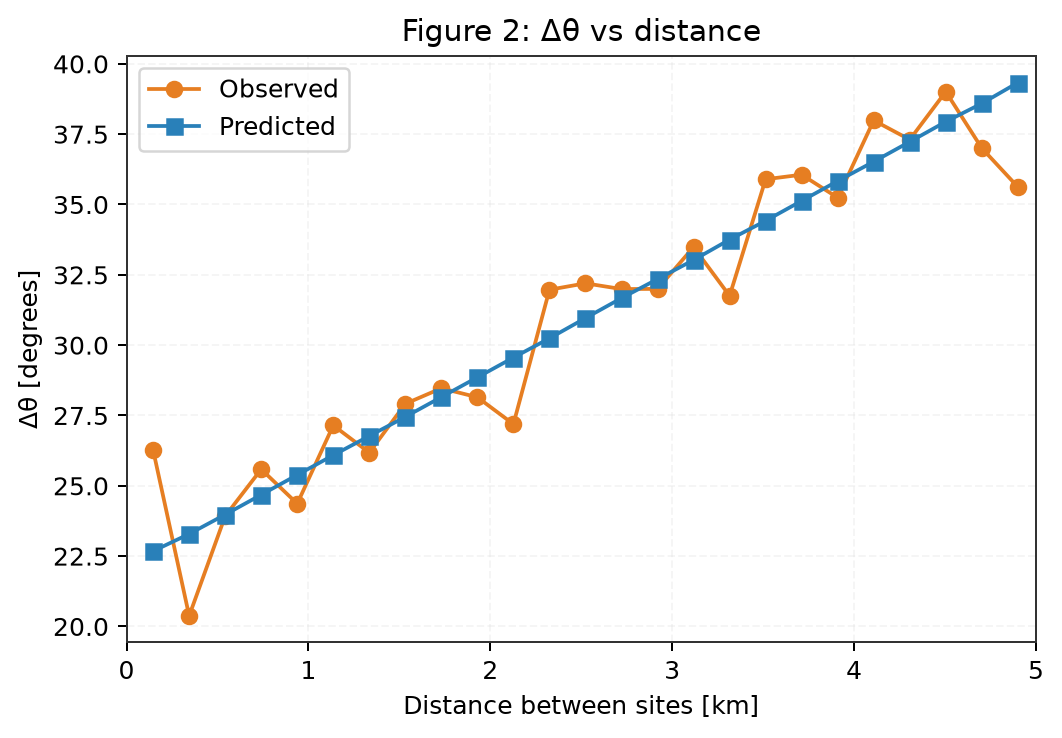

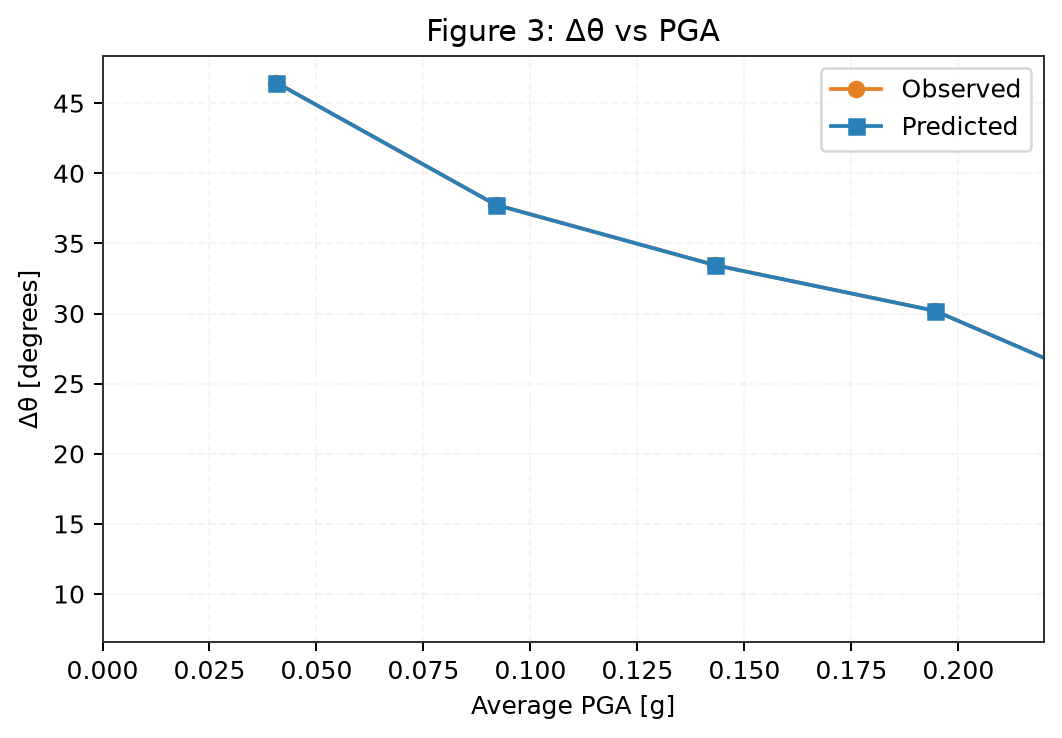

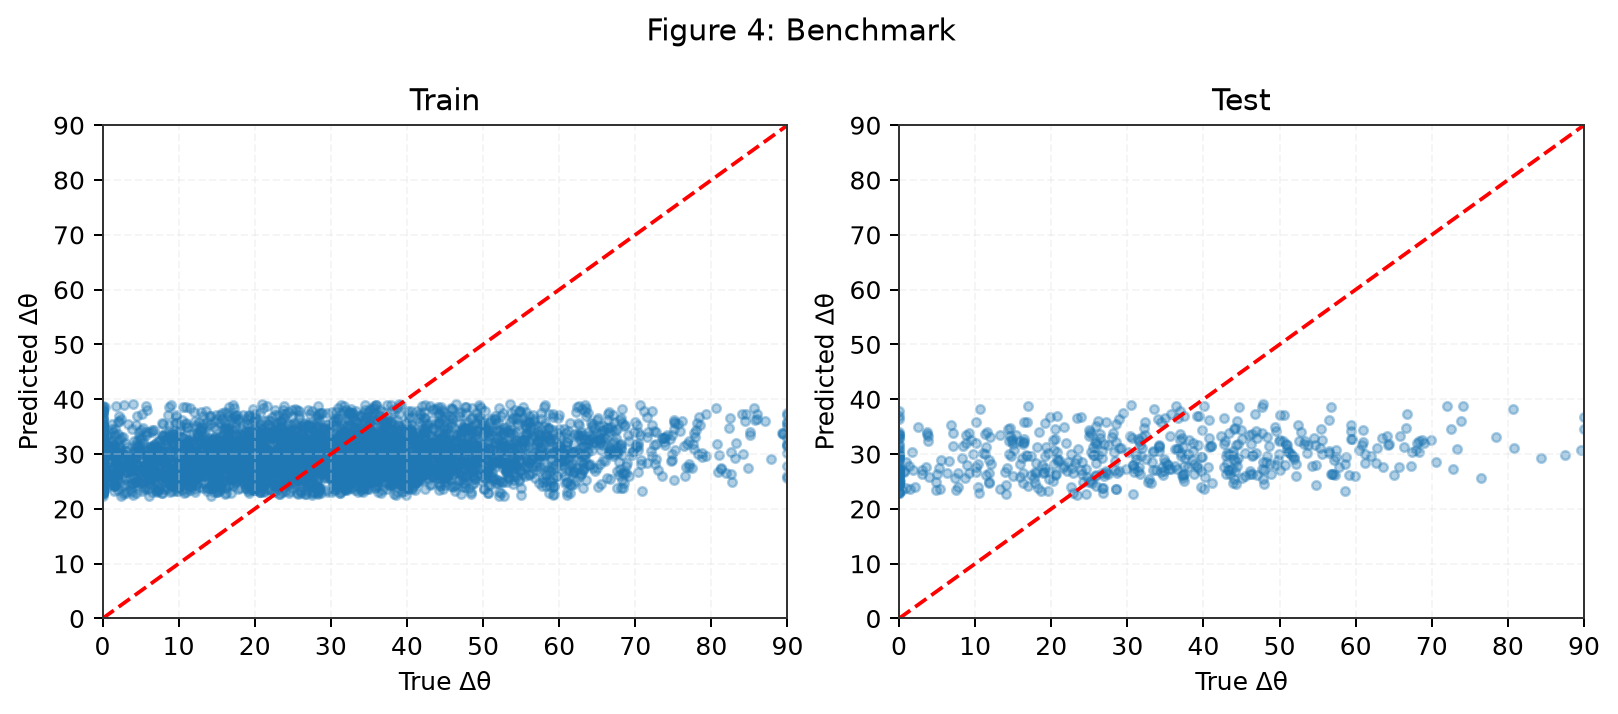

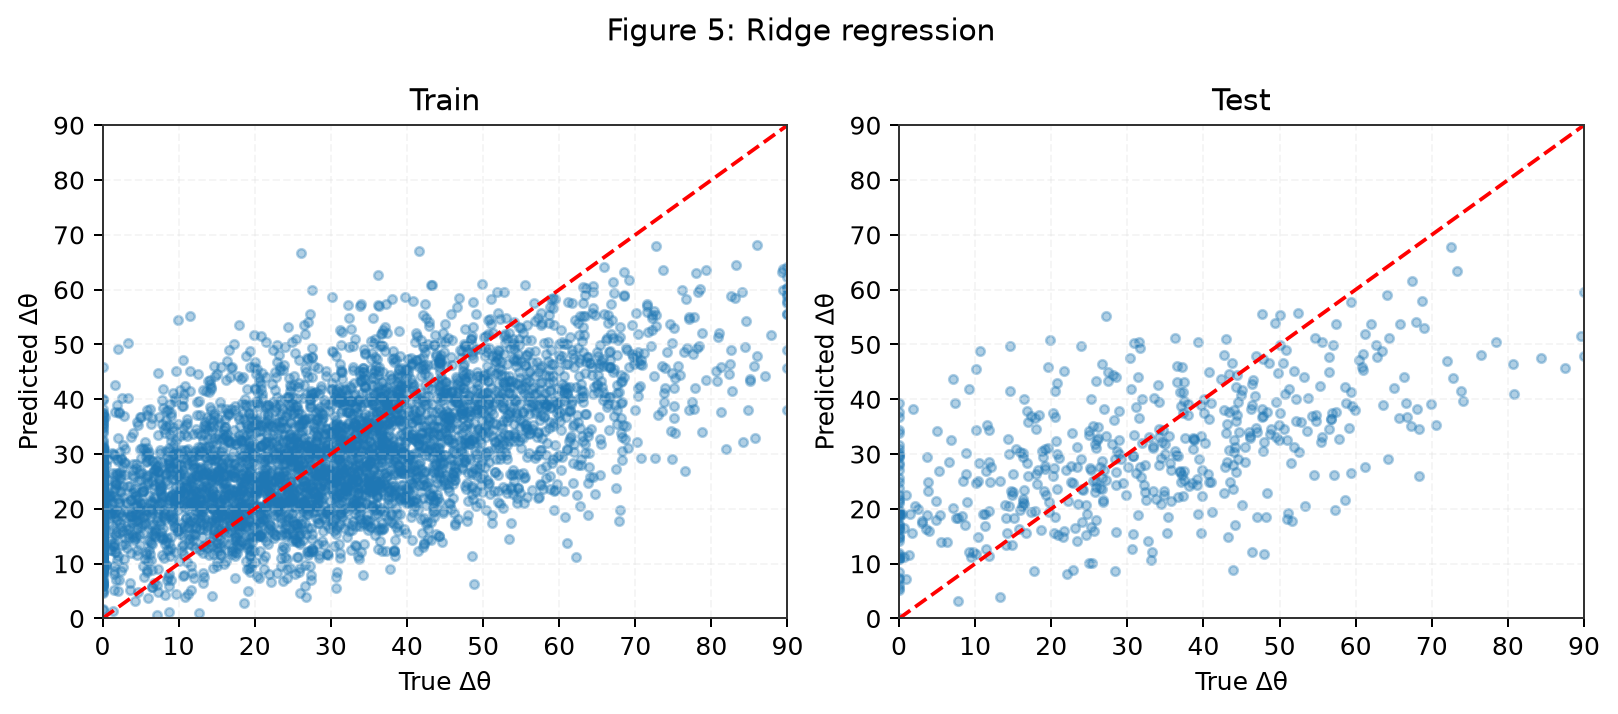

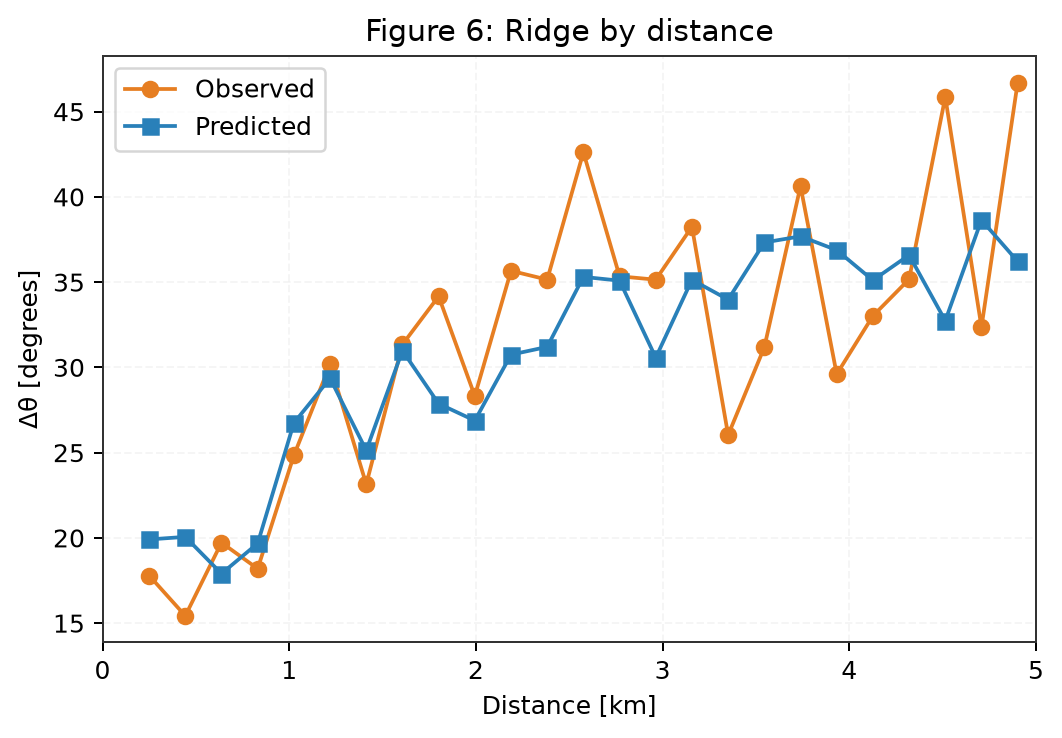

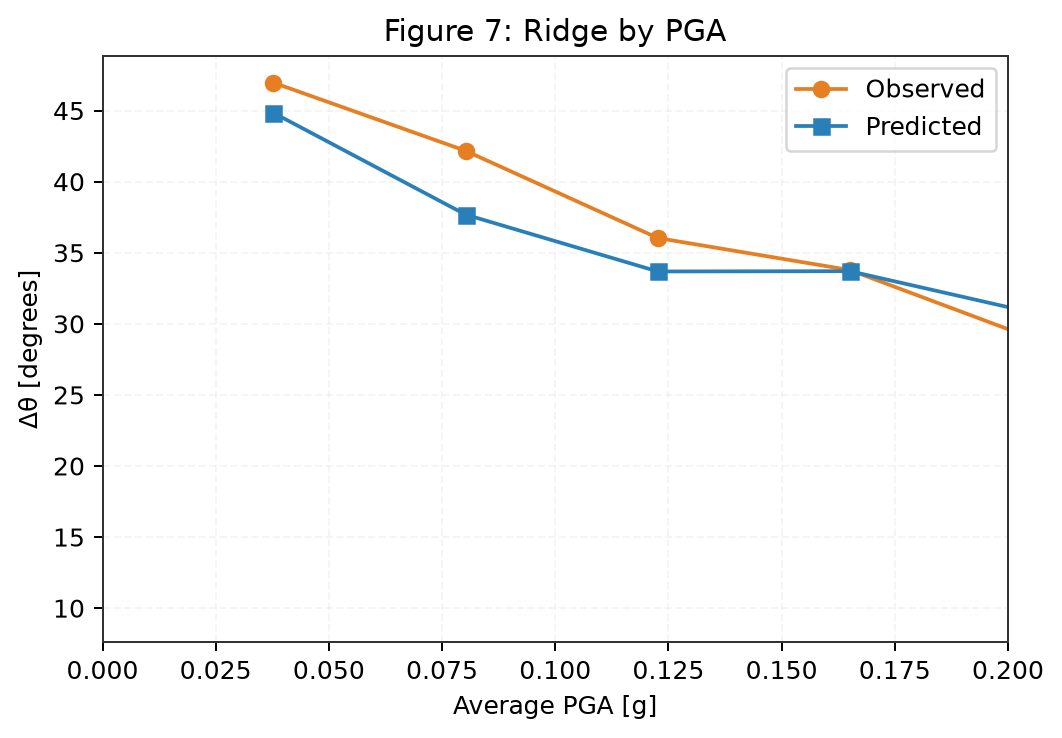

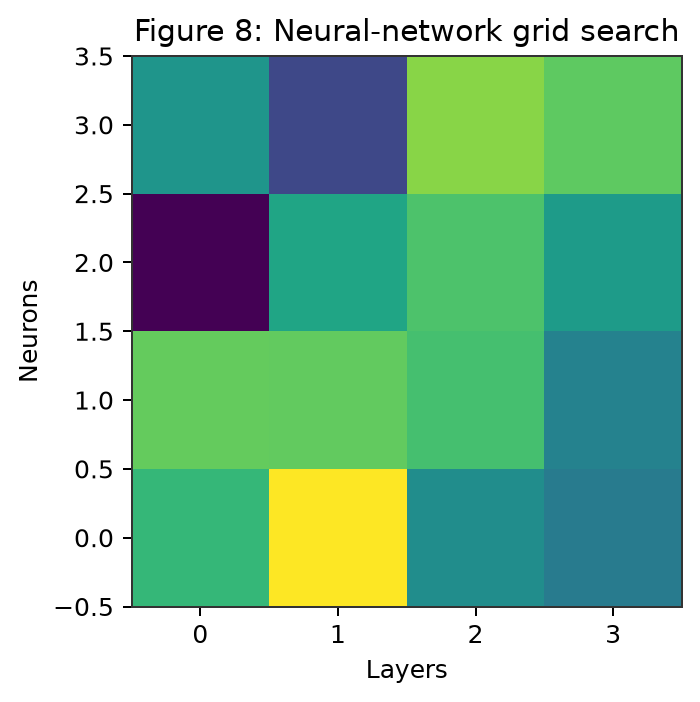

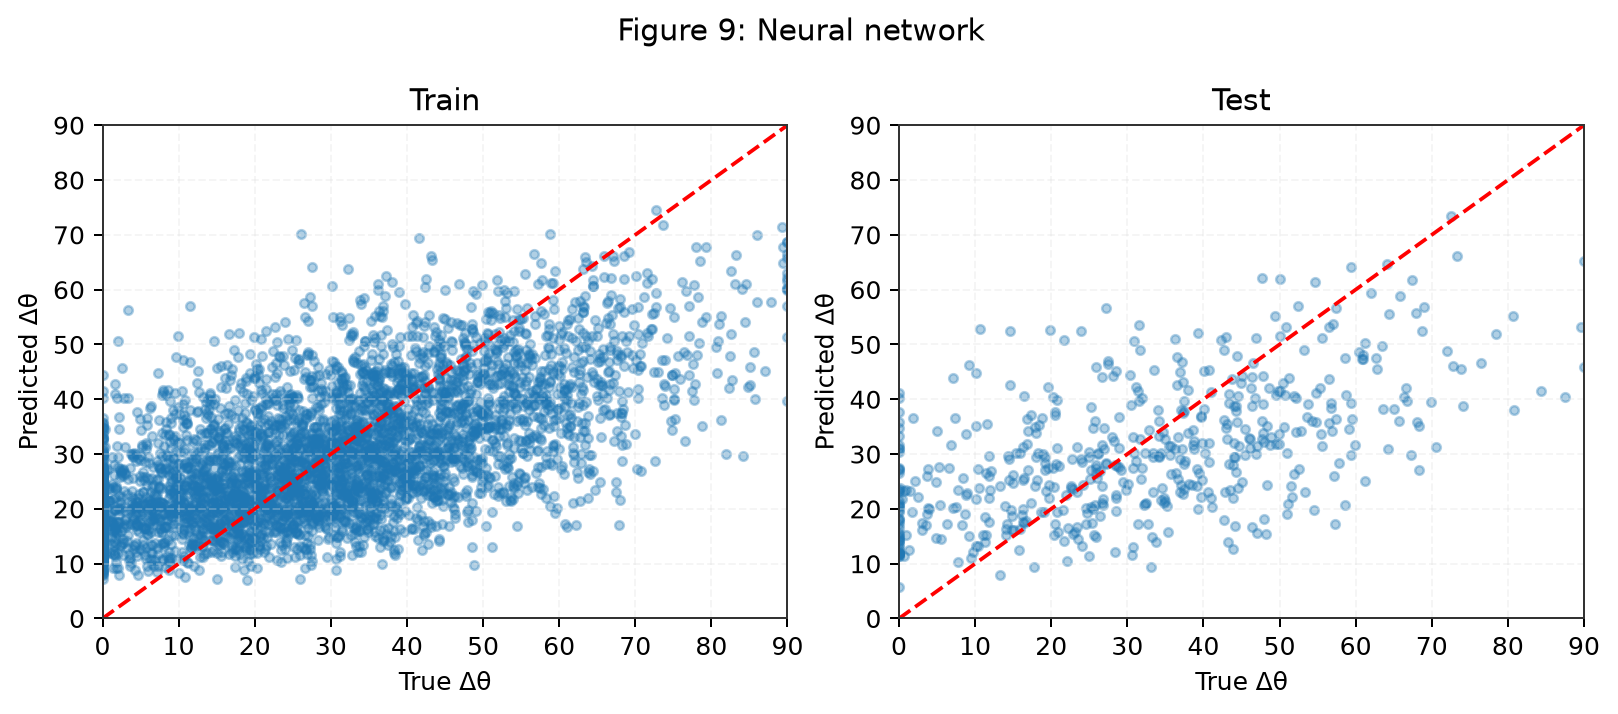

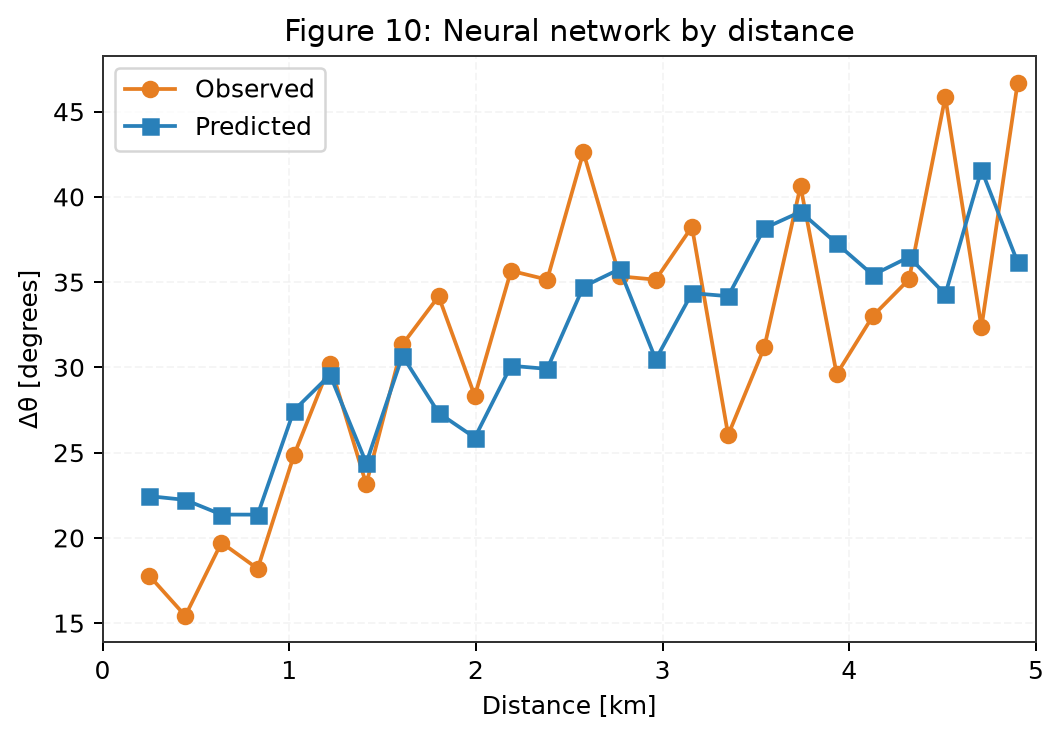

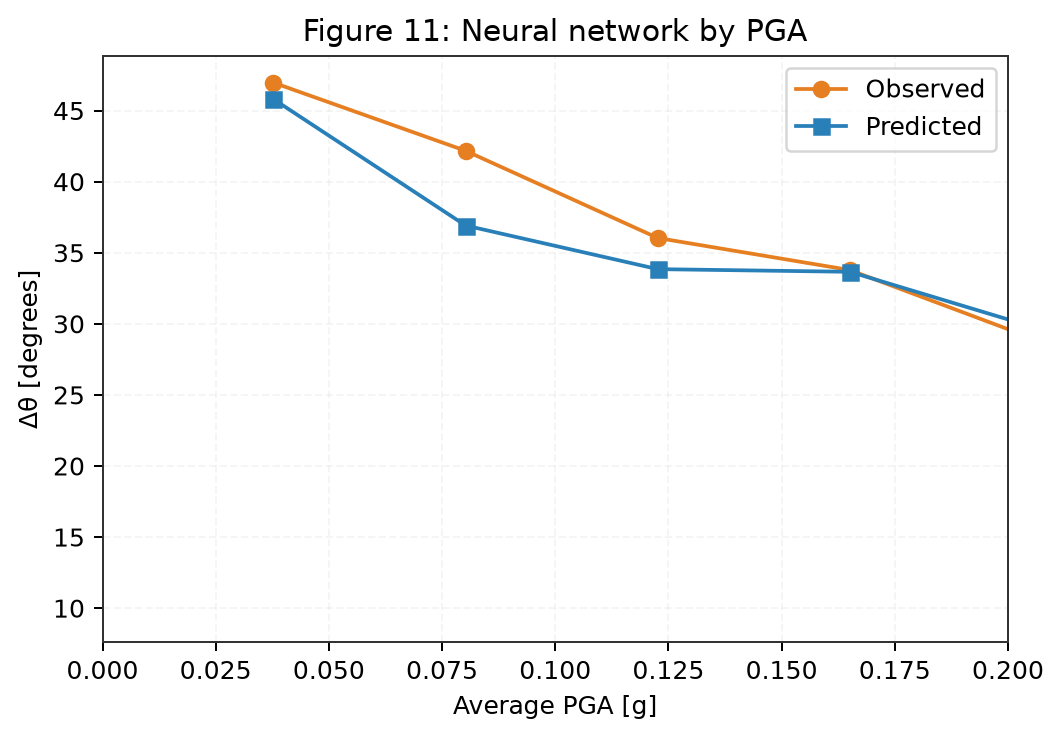

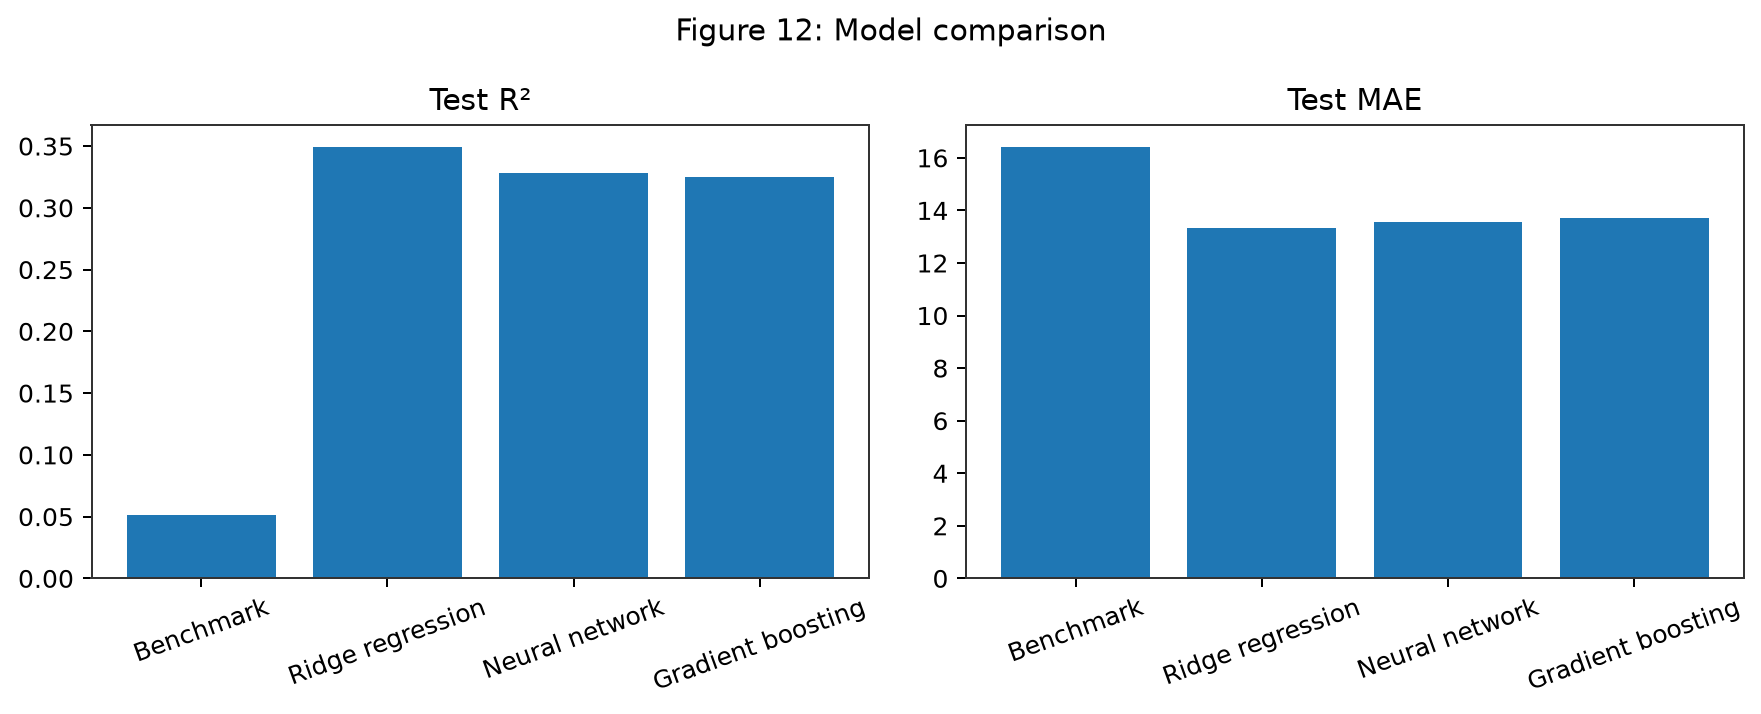

,train_r2,train_mae,test_r2,test_mae,test_rmse
Benchmark,0.037865,15.703611,0.051055,16.427452,19.951526
Ridge regression,0.349318,12.802725,0.349557,13.348829,16.518096
Neural network,0.380552,12.484752,0.328151,13.555249,16.787705
Gradient boosting,0.751158,7.856187,0.324710,13.708627,16.830635


In [21]:
evaluation_results = evaluate_models(trained_models)
results_table = pd.DataFrame(evaluation_results).T
display(results_table)

## 5. Run the built-in demonstration scenarios

In [14]:
predictor = Predictor(trained_models)
scenarios = [
    ('Scenario A: Near-Field Strong Shaking', 0.75, 0.18, 6.9, 420.0, 30.0),
    ('Scenario B: Mid-Range Separation', 2.50, 0.08, 6.3, 360.0, 110.0),
    ('Scenario C: Far Separation & Weak Shaking', 4.80, 0.02, 5.4, 290.0, 180.0),
]
for name, distance, pga, magnitude, vs30, diff_vs30 in scenarios:
    result = predictor.predict(distance, pga, magnitude, vs30, diff_vs30)
    print(f'\n{name}')
    print(f"  Regime: {result['regime']}")
    for model_name, value in result['predictions'].items():
        print(f'  {model_name}: {value:.2f}°')


Scenario A: Near-Field Strong Shaking
  Regime: High Wave Coherence & Strong Directivity
  Benchmark (Distance only): 32.64°
  Ridge Regression: 13.35°
  Deep Neural Network (MLP): 6.12°

Scenario B: Mid-Range Separation
  Regime: Intermediate Transition Zone
  Benchmark (Distance only): 39.32°
  Ridge Regression: 29.77°
  Deep Neural Network (MLP): 18.33°

Scenario C: Far Separation & Weak Shaking
  Regime: High Wave Dispersion / Scattered Wavefield
  Benchmark (Distance only): 48.10°
  Ridge Regression: 52.72°
  Deep Neural Network (MLP): 43.88°


## 6. Existing PDF deliverable

The PDF report was generated previously and is preserved at `deliverables/ML_MiniProject_Writeup.pdf`. Run All does not regenerate it.

In [15]:
print('The existing PDF report is preserved at deliverables/ML_MiniProject_Writeup.pdf.')
print('This notebook does not regenerate the PDF during Run All.')

The existing PDF report is preserved at deliverables/ML_MiniProject_Writeup.pdf.
This notebook does not regenerate the PDF during Run All.


## 7. Example single-point prediction

Change the four input values below to test another site-pair scenario after the pipeline has completed.

In [16]:
prediction = predictor.predict(
    distance_km=1.5,
    avg_pga=0.10,
    magnitude=6.5,
    avg_vs30=360.0
)
print(f"Physical regime: {prediction['regime']}")
display(pd.DataFrame([prediction['inputs']]))
display(pd.DataFrame([prediction['predictions']]))

Physical regime: Intermediate Transition Zone


,distance_km,avg_pga_g,magnitude,avg_vs30_ms,diff_vs30_ms
0,1.5,0.1,6.5,360.0,80.0


,Benchmark (Distance only),Ridge Regression,Deep Neural Network (MLP)
0,35.504177,22.791606,11.979478
